# VAE latent-space analysis — VCTK word embeddings

Loads the precomputed VAE latents (`AudioTensor`) + the VCTK labels and runs three studies:

1. **General latent-space analysis** — active vs. collapsed units, aggregate posterior vs. the prior, correlation structure, PCA / t-SNE / UMAP maps coloured per point.
2. **Gender — linear latent arithmetic** — a single gender *direction* (difference of class means), projection, an honest linear classifier, and a traversal that flips the prediction by *adding the vector*.
3. **Accent** — multinomial linear classification, confusion matrix, per-accent separability.

> **Read this before trusting any number below.** `GENDER` and `ACCENTS` are properties of the *speaker*, not of the individual word-utterance. Every word from `p225` carries the same label. So a random train/test split lets the classifier win by *recognising the speaker* rather than by reading gender/accent off the latent — the score looks great and means nothing. Everything here is therefore evaluated with **speaker-grouped cross-validation** (no speaker appears in both train and test). The notebook shows the leaky-vs-honest gap so you can see how big the difference is.

## 0 · Setup

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.ds_utils import load_audio_tensor, AudioTensor   # your project code

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             confusion_matrix, classification_report,
                             roc_auc_score, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=FutureWarning)

# ---- config (paths taken from your snippet) ----
EMB_DIR    = "/media/Data/jp_dir/sounds/vctk_words_v2/audio_val_in_latent_space"
LABELS_CSV = "/media/Data/jp_dir/sounds/vctk_words_v2/labels.csv"
LATENT_DIM   = 256
RANDOM_STATE = 0
rng = np.random.default_rng(RANDOM_STATE)

plt.rcParams.update({
    "figure.figsize": (8, 5), "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.25,
    "axes.spines.top": False, "axes.spines.right": False,
})

try:
    import umap                       # umap-learn
    HAVE_UMAP = True
except Exception:
    HAVE_UMAP = False
    print("umap-learn not installed -> skipping UMAP (pip install umap-learn to enable).")

umap-learn not installed -> skipping UMAP (pip install umap-learn to enable).


### Load latents + labels

In [2]:
encoded = load_audio_tensor(EMB_DIR)
labels  = pd.read_csv(LABELS_CSV)

print(f"{len(encoded.filenames)} filenames | data type: {type(encoded.data).__name__}")
print("examples:", encoded.filenames[:3])

24872 filenames | data type: Tensor
examples: ['p300_p300_099_word008.wav', 'p264_p264_091_word003.wav', 'p335_p335_024_word013.wav']


In [3]:
def to_matrix(data, latent_dim=LATENT_DIM):
    """Return a contiguous (N, latent_dim) float32 array.

    Handles torch tensors and >2-D latents. If the VAE produces a *temporal*
    latent (e.g. (N, 256, T) or (N, T, 256)) this mean-pools over time so each
    word becomes one 256-vector. Change the pooling here if you'd rather keep
    the sequence or use a different reduction.
    """
    arr = data.detach().cpu().numpy() if hasattr(data, "detach") else np.asarray(data)
    if arr.ndim == 1:
        arr = arr[None, :]
    if arr.ndim == 2:
        Z = arr
    else:
        cand = [ax for ax in range(1, arr.ndim) if arr.shape[ax] == latent_dim]
        if not cand:
            raise ValueError(f"no axis of size {latent_dim} in shape {arr.shape}; "
                             "set LATENT_DIM or pool manually.")
        lat_ax = cand[-1]
        other  = tuple(ax for ax in range(1, arr.ndim) if ax != lat_ax)
        Z = arr.mean(axis=other)
        print(f"pooled latents {arr.shape} -> {Z.shape} (mean over axes {other})")
    return np.ascontiguousarray(Z.astype(np.float32))

Z = to_matrix(encoded.data)
assert Z.shape[0] == len(encoded.filenames), (Z.shape, len(encoded.filenames))
print("Z:", Z.shape)

Z: (24872, 256)


In [4]:
def speaker_of(fname: str) -> str:
    # same rule as your _get_labels: leading pXXX token
    return os.path.splitext(os.path.basename(str(fname)))[0].split("_")[0]

# gender/accent are constant per speaker -> dedupe to one row per speaker
spk_attr = (labels.drop_duplicates("speaker_id")
                  .set_index("speaker_id")[["GENDER", "ACCENTS", "AGE", "REGION"]])

meta = pd.DataFrame({
    "filename": encoded.filenames,
    "speaker":  [speaker_of(f) for f in encoded.filenames],
}).join(spk_attr, on="speaker")

# best-effort word-level info via sample_id (optional, never required downstream)
try:
    key = pd.Series([os.path.splitext(os.path.basename(str(f)))[0] for f in encoded.filenames])
    w = labels.drop_duplicates("sample_id").set_index("sample_id")["word"]
    meta["word"] = key.map(w).values
except Exception as e:
    print("word-level join skipped:", e)

# drop anything we couldn't label, keep Z and meta aligned
missing = int(meta["GENDER"].isna().sum())
if missing:
    print(f"WARNING: {missing} samples had no matching speaker in labels.csv -> dropping.")
keep = meta["GENDER"].notna().to_numpy()
Z    = Z[keep]
meta = meta.loc[keep].reset_index(drop=True)

print(f"{len(meta)} samples | {meta.speaker.nunique()} speakers")
print("\nGENDER :", dict(meta.GENDER.value_counts()))
print("ACCENTS:", dict(meta.ACCENTS.value_counts()))

24872 samples | 109 speakers

GENDER : {'F': 14472, 'M': 10400}
ACCENTS: {'English': 7570, 'American': 4705, 'Scottish': 4394, 'Irish': 1883, 'Canadian': 1756, 'NorthernIrish': 1356, 'SouthAfrican': 985, 'Indian': 704, 'Australian English': 441, 'British': 323, 'NewZealand English': 291, 'Unknown': 256, 'Welsh': 208}


In [5]:
# shared scatter helper — one colour per category, used everywhere below
def scatter2d(XY, cats, title, ax=None, s=8, max_legend=14):
    ax = ax or plt.gca()
    cat = pd.Categorical(pd.Series(cats).astype(str))
    cmap = plt.get_cmap("tab20" if len(cat.categories) > 10 else "tab10")
    for i, c in enumerate(cat.categories):
        m = cat.codes == i
        ax.scatter(XY[m, 0], XY[m, 1], s=s, alpha=0.6, linewidths=0,
                   color=cmap(i % cmap.N),
                   label=c if i < max_legend else None)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
    if len(cat.categories) <= max_legend:
        ax.legend(markerscale=2, fontsize=8, frameon=False, loc="best")
    return ax

## 1 · General latent-space analysis

A VAE latent isn't just a feature vector — it's trained against an $\mathcal{N}(0, I)$ prior, so two things are worth checking before any classification:

* **Active units.** Many dimensions usually *collapse* (variance ≈ 0) — the encoder ignores them. The count of active dims is the latent space's effective size.
* **Aggregate posterior.** Pooling the posterior means across the dataset should look roughly Gaussian if the prior is being matched.

global mean = -0.004  (prior 0)   global std = 0.932  (prior 1)
active dims (var > 0.01): 256 / 256


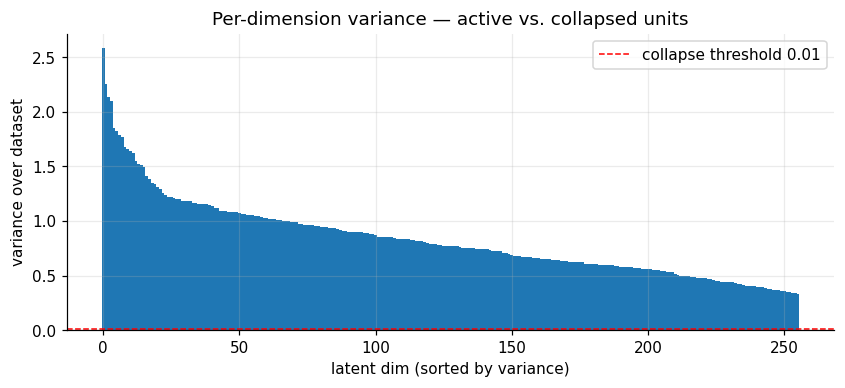

In [6]:
mu, var = Z.mean(0), Z.var(0)
print(f"global mean = {Z.mean():+.3f}  (prior 0)   global std = {Z.std():.3f}  (prior 1)")

THR = 0.01
active = var > THR
print(f"active dims (var > {THR}): {active.sum()} / {LATENT_DIM}")

order = np.argsort(var)[::-1]
plt.figure(figsize=(9, 3.5))
plt.bar(range(LATENT_DIM), var[order], width=1.0)
plt.axhline(THR, color="r", ls="--", lw=1, label=f"collapse threshold {THR}")
plt.xlabel("latent dim (sorted by variance)"); plt.ylabel("variance over dataset")
plt.title("Per-dimension variance — active vs. collapsed units"); plt.legend(); plt.show()

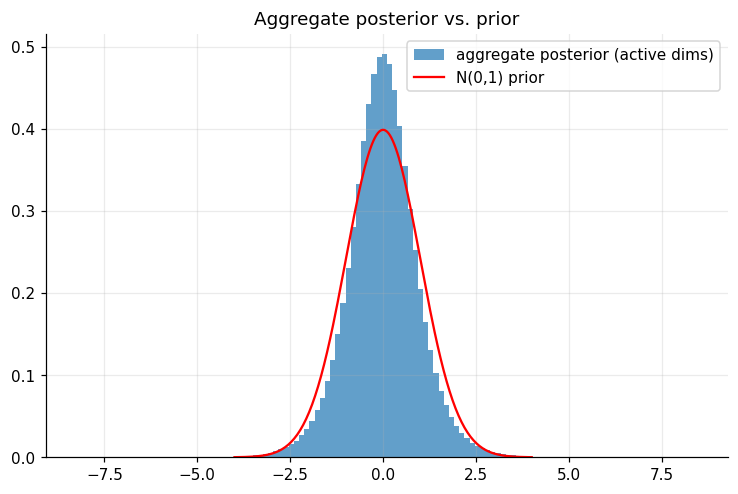

In [7]:
vals = Z[:, active].ravel() if active.any() else Z.ravel()
plt.figure()
plt.hist(vals, bins=120, density=True, alpha=0.7, label="aggregate posterior (active dims)")
xs = np.linspace(-4, 4, 200)
plt.plot(xs, np.exp(-xs**2 / 2) / np.sqrt(2*np.pi), "r", lw=1.5, label="N(0,1) prior")
plt.title("Aggregate posterior vs. prior"); plt.legend(); plt.show()

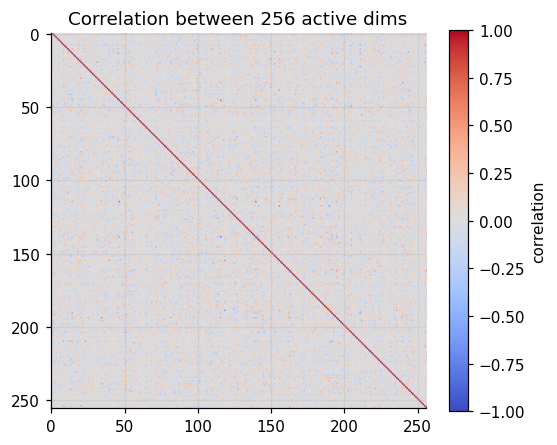

mean |off-diagonal correlation| = 0.073 (low => dims are fairly disentangled)


In [8]:
A = Z[:, active]
C = np.corrcoef(A, rowvar=False)
plt.figure(figsize=(5.5, 4.5))
plt.imshow(C, vmin=-1, vmax=1, cmap="coolwarm")
plt.colorbar(label="correlation")
plt.title(f"Correlation between {int(active.sum())} active dims"); plt.show()

off = C[~np.eye(C.shape[0], dtype=bool)]
print(f"mean |off-diagonal correlation| = {np.abs(off).mean():.3f} "
      "(low => dims are fairly disentangled)")

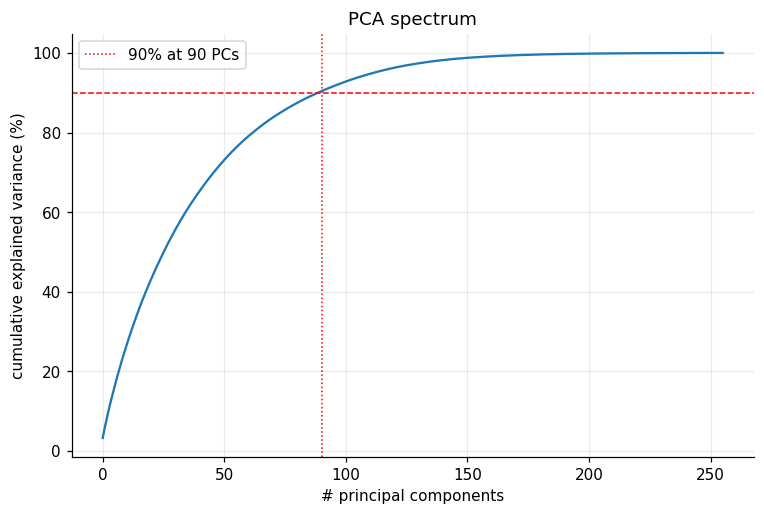

In [9]:
Zs  = StandardScaler().fit_transform(Z)
pca = PCA(random_state=RANDOM_STATE).fit(Zs)
cum = np.cumsum(pca.explained_variance_ratio_) * 100
k90 = int(np.argmax(cum >= 90) + 1)

plt.figure()
plt.plot(cum)
plt.axhline(90, color="r", ls="--", lw=1)
plt.axvline(k90, color="r", ls=":", lw=1, label=f"90% at {k90} PCs")
plt.xlabel("# principal components"); plt.ylabel("cumulative explained variance (%)")
plt.title("PCA spectrum"); plt.legend(); plt.show()

### 2-D maps, coloured per point
PCA is linear; t-SNE / UMAP are non-linear. If gender splits cleanly even in 2-D, expect the linear classifier in §2 to do well.

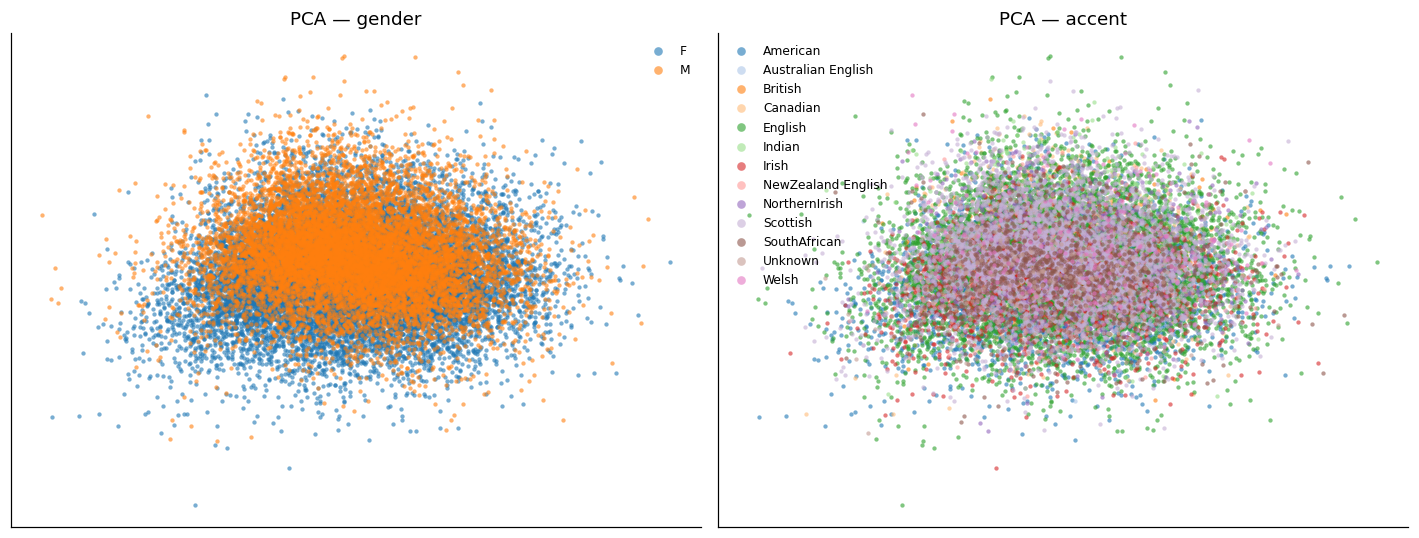

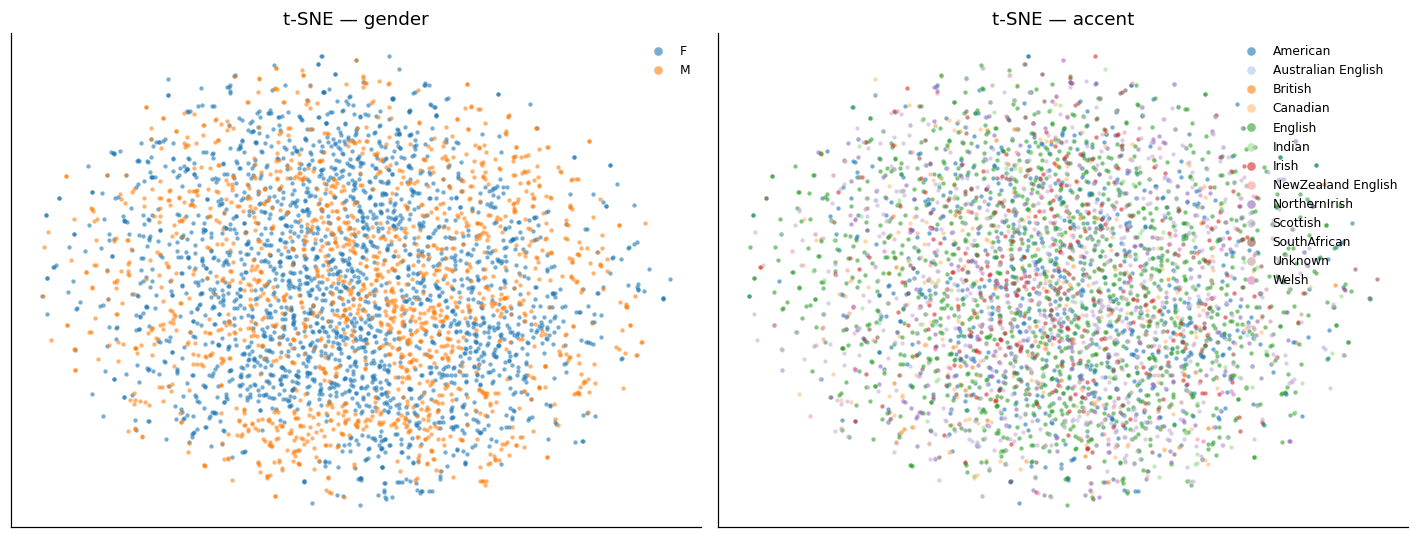

In [10]:
N   = len(Zs)
sub = np.arange(N) if N <= 4000 else rng.choice(N, 4000, replace=False)

emb = {}
emb["PCA"]  = (PCA(2, random_state=RANDOM_STATE).fit_transform(Zs), np.arange(N))
emb["t-SNE"] = (TSNE(2, init="pca", perplexity=30, random_state=RANDOM_STATE)
                .fit_transform(Zs[sub]), sub)
if HAVE_UMAP:
    emb["UMAP"] = (umap.UMAP(n_components=2, random_state=RANDOM_STATE)
                   .fit_transform(Zs), np.arange(N))

for name, (XY, idx) in emb.items():
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    scatter2d(XY, meta.GENDER.iloc[idx],  f"{name} — gender", ax=ax[0])
    scatter2d(XY, meta.ACCENTS.iloc[idx], f"{name} — accent", ax=ax[1])
    plt.tight_layout(); plt.show()

## 2 · Gender — linear latent arithmetic

Two ways to get a **gender direction**, both linear:

* **Difference of class means** $\;v = \mu_{F} - \mu_{M}\;$ — the classic word2vec-style "attribute vector". It lives in raw latent space, so you can *add* it to any point.
* **Logistic-regression weight vector** — the normal to the learned decision hyperplane.

If those two directions point the same way (high cosine similarity), gender is encoded along *one consistent linear axis* — exactly what makes latent arithmetic work.

||gender axis|| = 3.640
AUC of the raw 1-D projection = 0.972


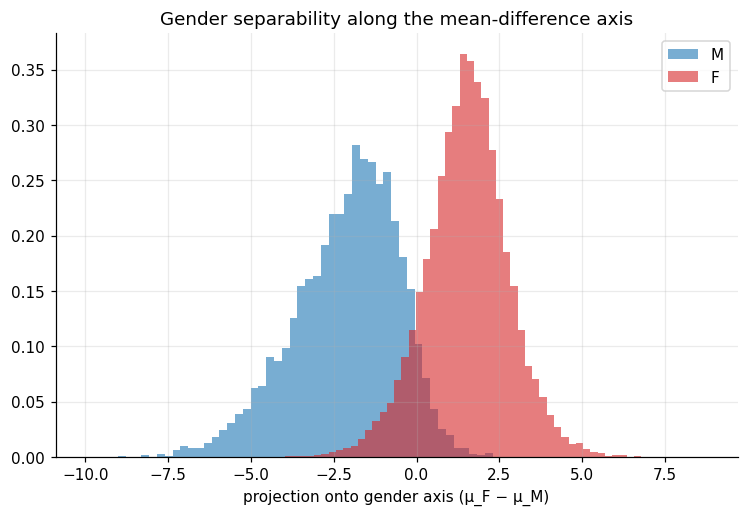

In [11]:
y_gender = (meta.GENDER.str.upper().str[0] == "F").astype(int).to_numpy()  # 1=F, 0=M
groups   = meta.speaker.to_numpy()

mu_f, mu_m = Z[y_gender == 1].mean(0), Z[y_gender == 0].mean(0)
v_gender = mu_f - mu_m
v_unit   = v_gender / np.linalg.norm(v_gender)

proj = (Z - Z.mean(0)) @ v_unit
print(f"||gender axis|| = {np.linalg.norm(v_gender):.3f}")
print(f"AUC of the raw 1-D projection = {roc_auc_score(y_gender, proj):.3f}")

plt.figure()
for c, lab, col in [(0, "M", "#1f77b4"), (1, "F", "#d62728")]:
    plt.hist(proj[y_gender == c], bins=60, density=True, alpha=0.6, color=col, label=lab)
plt.xlabel("projection onto gender axis (μ_F − μ_M)")
plt.title("Gender separability along the mean-difference axis"); plt.legend(); plt.show()

### Honest (speaker-grouped) vs. leaky (random) linear classifier

In [12]:
def cv_predict(X, y, groups, grouped=True, n_splits=5):
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    if grouped:
        splits = GroupKFold(n_splits).split(X, y, groups)
    else:
        splits = StratifiedKFold(n_splits, shuffle=True,
                                 random_state=RANDOM_STATE).split(X, y)
    yhat = np.zeros_like(y); yprob = np.zeros(len(y))
    for tr, te in splits:
        clf.fit(X[tr], y[tr])
        yhat[te]  = clf.predict(X[te])
        yprob[te] = clf.predict_proba(X[te])[:, 1]
    return yhat, yprob

yh,  yp  = cv_predict(Z, y_gender, groups, grouped=True)
yhL, _   = cv_predict(Z, y_gender, groups, grouped=False)

print("speaker-grouped  | acc {:.3f}  bal-acc {:.3f}  AUC {:.3f}".format(
    accuracy_score(y_gender, yh), balanced_accuracy_score(y_gender, yh),
    roc_auc_score(y_gender, yp)))
print("random   (LEAKY) | acc {:.3f}  bal-acc {:.3f}".format(
    accuracy_score(y_gender, yhL), balanced_accuracy_score(y_gender, yhL)))
print("\nThe random split is optimistic: it can recognise speakers it also saw in training.")

speaker-grouped  | acc 0.976  bal-acc 0.974  AUC 0.995
random   (LEAKY) | acc 0.977  bal-acc 0.976

The random split is optimistic: it can recognise speakers it also saw in training.


In [13]:
# recover the logistic direction in raw latent space and compare to the mean-diff axis
scaler = StandardScaler().fit(Z)
lr = LogisticRegression(max_iter=2000).fit(scaler.transform(Z), y_gender)
w_raw  = lr.coef_.ravel() / scaler.scale_          # undo standardisation
w_unit = w_raw / np.linalg.norm(w_raw)
print(f"cosine(mean-diff axis, logistic axis) = {float(w_unit @ v_unit):+.3f}")

cosine(mean-diff axis, logistic axis) = +0.633


### Latent arithmetic: traverse the gender direction

Walk a handful of points along $z + \alpha\,\sigma\,\hat v$ and watch the classifier's $P(\text{Female})$ slide across the boundary. The attribute moves *linearly* — adding the vector is enough to change the prediction.

If you still have the VAE decoder loaded you can decode any shifted `z` back to audio to actually **hear** the change (hook at the bottom of the cell).

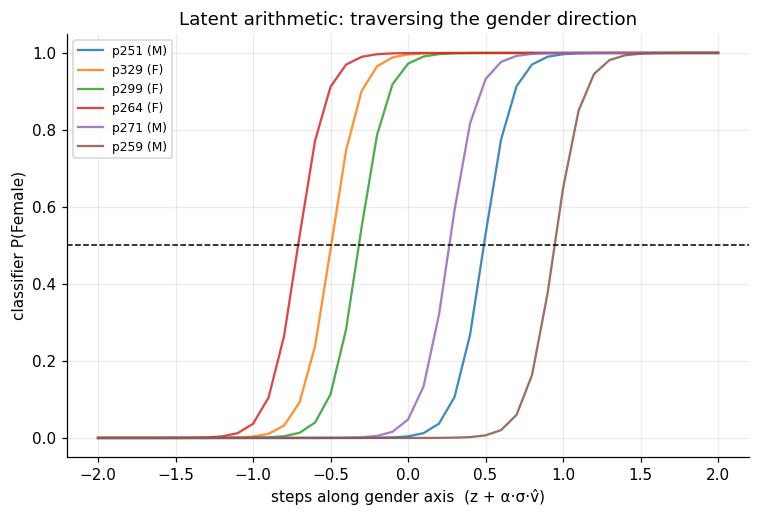

In [14]:
step  = v_unit * proj.std()                 # one step ≈ 1 std along the axis
alpha = np.linspace(-2, 2, 41)
picks = rng.choice(len(Z), 6, replace=False)

plt.figure()
for i in picks:
    zs = Z[i][None, :] + alpha[:, None] * step[None, :]
    p  = lr.predict_proba(scaler.transform(zs))[:, 1]
    plt.plot(alpha, p, alpha=0.85,
             label=f"{meta.speaker[i]} ({'F' if y_gender[i] else 'M'})")
plt.axhline(0.5, color="k", ls="--", lw=1)
plt.xlabel("steps along gender axis  (z + α·σ·v̂)")
plt.ylabel("classifier P(Female)")
plt.title("Latent arithmetic: traversing the gender direction")
plt.legend(fontsize=8); plt.show()

# --- OPTIONAL: decode a shifted latent back to audio ---
# from src.model import load_vae            # your decoder
# vae = load_vae(...)
# z_shift = Z[picks[0]] + 1.5 * step
# audio = vae.decode(torch.tensor(z_shift)[None].to(device))
# import IPython.display as ipd; ipd.Audio(audio.squeeze().cpu().numpy(), rate=SR)

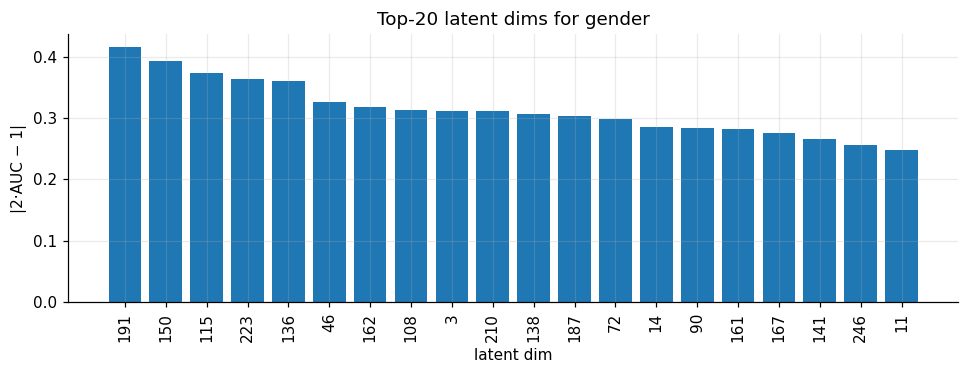

In [15]:
# which dims carry gender? per-dim |2·AUC − 1|
dim_auc = np.array([roc_auc_score(y_gender, Z[:, d]) for d in range(LATENT_DIM)])
imp = np.abs(dim_auc - 0.5) * 2
top = np.argsort(imp)[::-1][:20]

plt.figure(figsize=(9, 3.5))
plt.bar(range(20), imp[top])
plt.xticks(range(20), top, rotation=90)
plt.xlabel("latent dim"); plt.ylabel("|2·AUC − 1|")
plt.title("Top-20 latent dims for gender"); plt.tight_layout(); plt.show()

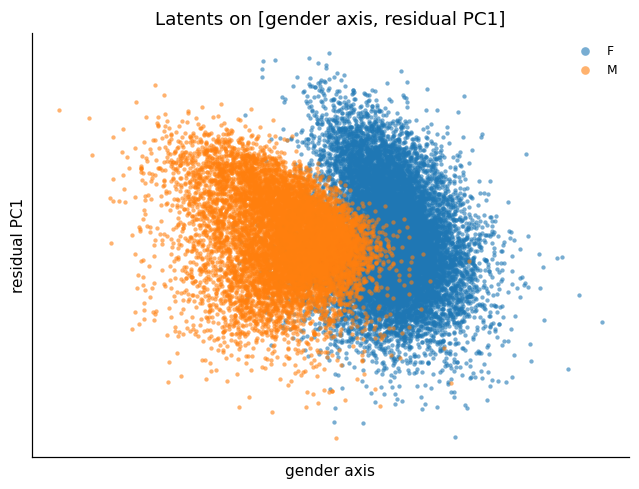

In [16]:
# a clean "per-point" view: x = gender axis, y = leading PC of the residual
Zc    = Z - Z.mean(0)
resid = Zc - np.outer(Zc @ v_unit, v_unit)
y2    = PCA(1, random_state=RANDOM_STATE).fit_transform(resid).ravel()

plt.figure(figsize=(7, 5))
scatter2d(np.column_stack([proj, y2]), meta.GENDER,
          "Latents on [gender axis, residual PC1]")
plt.xlabel("gender axis"); plt.ylabel("residual PC1"); plt.show()

## 3 · Accent

Harder than gender: multi-class and **heavily imbalanced** (VCTK is mostly English/Scottish). So:

* keep only accents with enough *distinct speakers* for grouped CV to be meaningful,
* report **balanced accuracy** and per-class metrics, not raw accuracy,
* compare against both uniform chance and the by-frequency baseline.

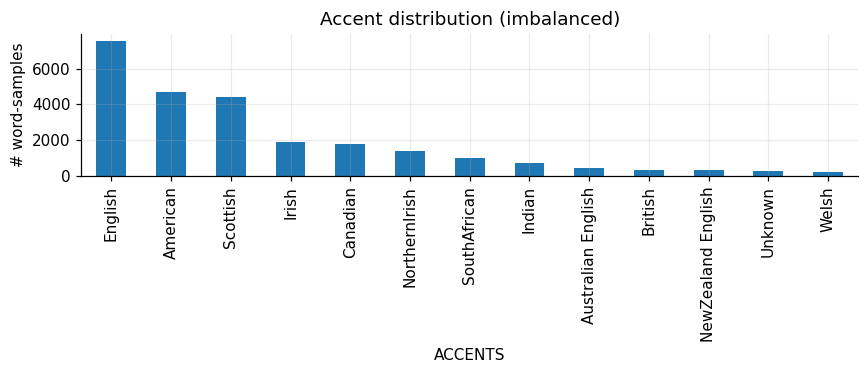

ACCENTS
English               7570
American              4705
Scottish              4394
Irish                 1883
Canadian              1756
NorthernIrish         1356
SouthAfrican           985
Indian                 704
Australian English     441
British                323
NewZealand English     291
Unknown                256
Welsh                  208
Name: count, dtype: int64


In [17]:
acc_counts = meta.ACCENTS.value_counts()
plt.figure(figsize=(8, 3.5))
acc_counts.plot.bar()
plt.ylabel("# word-samples"); plt.title("Accent distribution (imbalanced)")
plt.tight_layout(); plt.show()
print(acc_counts)

In [18]:
MIN_SPK = 3
spk_per_acc = meta.groupby("ACCENTS").speaker.nunique()
keep_acc = spk_per_acc[spk_per_acc >= MIN_SPK].index
mask = meta.ACCENTS.isin(keep_acc).to_numpy()
print(f"keeping accents with >= {MIN_SPK} speakers:", list(keep_acc))

Za = Z[mask]
ma = meta.loc[mask].reset_index(drop=True)
le = LabelEncoder().fit(ma.ACCENTS)
yA = le.transform(ma.ACCENTS)
ga = ma.speaker.to_numpy()

keeping accents with >= 3 speakers: ['American', 'Canadian', 'English', 'Indian', 'Irish', 'NorthernIrish', 'Scottish', 'SouthAfrican']


In [19]:
n_splits = max(2, min(5, int(spk_per_acc[keep_acc].min())))
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))

yhat = np.empty_like(yA)
for tr, te in GroupKFold(n_splits).split(Za, yA, ga):
    clf.fit(Za[tr], yA[tr])
    yhat[te] = clf.predict(Za[te])

freq = pd.Series(yA).value_counts(normalize=True)
print(f"accent — speaker-grouped {n_splits}-fold")
print(f"  accuracy      {accuracy_score(yA, yhat):.3f}")
print(f"  balanced acc  {balanced_accuracy_score(yA, yhat):.3f}")
print(f"  chance        {1/len(le.classes_):.3f} uniform / {(freq**2).sum():.3f} by-frequency\n")
print(classification_report(yA, yhat, target_names=le.classes_))

accent — speaker-grouped 3-fold
  accuracy      0.262
  balanced acc  0.134
  chance        0.125 uniform / 0.199 by-frequency

               precision    recall  f1-score   support

     American       0.25      0.28      0.26      4705
     Canadian       0.06      0.03      0.04      1756
      English       0.32      0.47      0.38      7570
       Indian       0.01      0.00      0.01       704
        Irish       0.08      0.02      0.03      1883
NorthernIrish       0.00      0.00      0.00      1356
     Scottish       0.30      0.26      0.28      4394
 SouthAfrican       0.00      0.00      0.00       985

     accuracy                           0.26     23353
    macro avg       0.13      0.13      0.13     23353
 weighted avg       0.22      0.26      0.23     23353



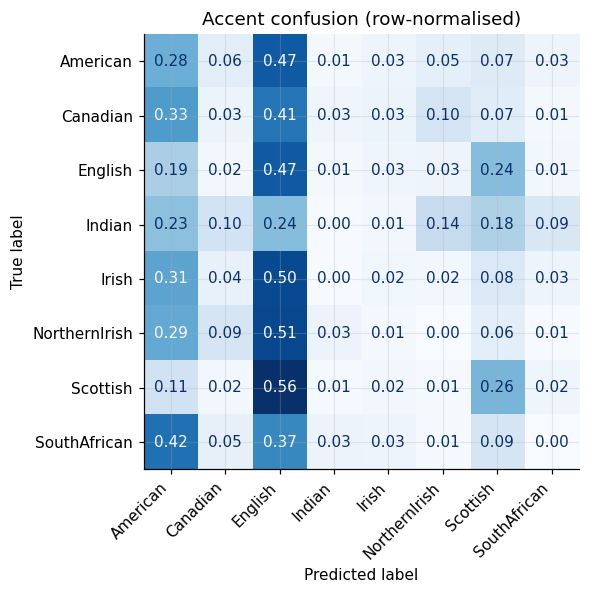

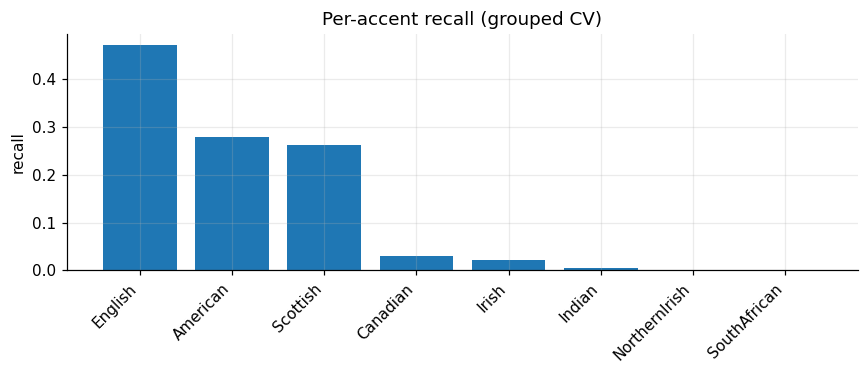

In [20]:
cm = confusion_matrix(yA, yhat, normalize="true")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay(cm, display_labels=le.classes_).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format=".2f")
plt.xticks(rotation=45, ha="right")
plt.title("Accent confusion (row-normalised)"); plt.tight_layout(); plt.show()

recall = np.diag(cm); o = np.argsort(recall)[::-1]
plt.figure(figsize=(8, 3.5))
plt.bar(range(len(recall)), recall[o])
plt.xticks(range(len(recall)), le.classes_[o], rotation=45, ha="right")
plt.ylabel("recall"); plt.title("Per-accent recall (grouped CV)")
plt.tight_layout(); plt.show()

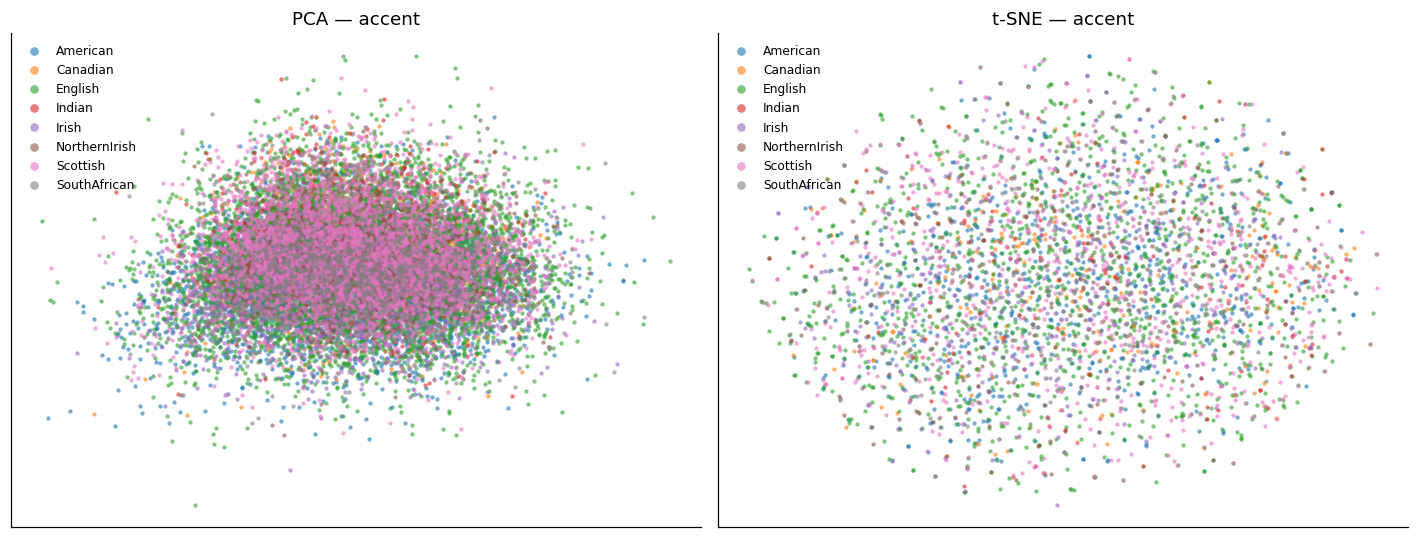

In [21]:
# 2-D maps coloured by accent (kept classes only)
Zas = StandardScaler().fit_transform(Za)
Na  = len(Zas); suba = np.arange(Na) if Na <= 4000 else rng.choice(Na, 4000, replace=False)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
scatter2d(PCA(2, random_state=RANDOM_STATE).fit_transform(Zas),
          ma.ACCENTS, "PCA — accent", ax=ax[0])
scatter2d(TSNE(2, init="pca", perplexity=30, random_state=RANDOM_STATE).fit_transform(Zas[suba]),
          ma.ACCENTS.iloc[suba], "t-SNE — accent", ax=ax[1])
plt.tight_layout(); plt.show()

## 4 · How to read the results

* **§1** tells you the *effective* size of the latent (active units) and whether the encoder uses the prior. Gender/accent classification can only succeed in the active subspace.
* **§2** — if the mean-difference axis and the logistic axis are well aligned and the traversal flips $P(F)$ smoothly, gender is encoded **linearly along one direction**: clean latent arithmetic. The honest (grouped) AUC is the number to report.
* **§3** — accent is the real test of structure. Compare balanced accuracy to the by-frequency baseline; the confusion matrix shows *which* accents the latent actually separates (often the well-sampled, acoustically distinct ones) vs. those it folds into the majority class.

**Knobs:** `to_matrix` pooling (if your latents are temporal you may not want a plain mean), `THR` for the active-unit cutoff, `MIN_SPK` for which accents to keep, and `C` in the logistic regressions if you want to probe how much regularisation the signal tolerates.